# ChiliEdgeNet-C14 — (1/3) Train & Baseline

Notebook **train** 2 model chinh: Scenario 1 (baseline) + Scenario 2 (augmented = model de xuat **ChiliEdgeNet**).

**Output quan trong (dung cho NB2 & NB3):** `c14_s1.pth`, `c14_s2.pth`.
Sau khi chay xong -> **Save Version** de 2 file nay vao output, roi Add Input o NB2/NB3.

Cac phan phan tich (nhieu / XAI / latency / ablation / nen) tach sang NB2, NB3.

**Model:** *ChiliEdgeNet-C14* — mo hinh de xuat, dua tren nen tang *RTR_Lite_MobileNetV2* (Duhan et al., Current Plant Biology 42 (2025) 100459)

| Hyperparameter | Value | Source (cell trong notebook nay) |
|---|---|---|
| Framework | PyTorch | Cell `c002` |
| Input size | 224×224 | Cell `c003` (`IMG_SIZE`) |
| Batch size | 32 | Cell `c003` |
| Epochs | 30 | Cell `c003` |
| Optimizer | Adam, 2 nhom LR (backbone 1e-4 / phan moi 1e-3) | Cell `c003`, `eb2c0ec4` (`make_optimizer`) |
| LR schedule | Linear warmup 10% epoch dau -> cosine decay ve 0 | Cell `eb2c0ec4` (`make_scheduler`) |
| Loss | CrossEntropyLoss + label smoothing 0,05 (+ class weight neu lech lop >= 1,5x) | Cell `c004`, `c003`, `eb2c0ec4` |
| Transfer learning | MobileNetV2 `ImageNet1K_V1` | Cell `f3e6d84c` |
| Dropout | 0,1 (trong Transformer) + 0,2 (truoc lop phan loai) | Cell `c003`, `f3e6d84c` |
| Total params | **671.173** | Cell `c006` (torchinfo) |

**Architecture modifications on MobileNetV2:**
- Giu `features[1:14]` (luoi dac trung 14×14, 96 kenh), **bo `features[14:19]`** (toan bo tang stride-32 cuoi cua MobileNetV2)
- Sau backbone: `Conv1x1` giam kenh 96 -> 128 + `BatchNorm` + `GELU` (chieu ve `embed_dim`)
- Trai phang luoi 14×14 thanh **196 token**, dua qua **1 khoi Tiny-LLM Transformer**: `RMSNorm` + **2D-RoPE** (0 tham so hoc) + **Grouped Query Attention** (4 query head, 2 kv-head) + `GELU MLP` (ty le mo rong 2.0)
- Classifier: `RMSNorm` -> mean-pool 196 token -> `Dropout(0.2)` -> `Linear(128, NUM_CLASSES)`

*Khac biet chinh so voi RTR_Lite_MobileNetV2 (~1.050.547 tham so):* thay vi giu nguyen do sau MobileNetV2 va gan them `TripletAttention` + `RES_Block`, ChiliEdgeNet **cat ngan backbone hon** (dung den `features[13]` thay vi gan het) va thay co che attention/residual kieu CNN bang **1 khoi Transformer nho kieu LLM** (RoPE-2D + GQA + RMSNorm) — nhe hon 35% (671K so 1,05M) trong khi van giu luoi khong gian 14×14 min hon.

In [1]:
!pip install -q torchinfo

In [2]:
import os, gc, warnings, math, random
import numpy as np
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as T
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader
from torchinfo import summary as torchinfo_summary
from sklearn.metrics import classification_report, confusion_matrix, f1_score, recall_score
from sklearn.utils.class_weight import compute_class_weight
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings('ignore')

# Chi can doi gia tri nay de chay mot seed moi.
SEED = 42

def set_seed(seed=SEED):
    """Co dinh Python / NumPy / PyTorch CPU + CUDA de tai lap."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed()
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE} | seed={SEED}')

Device: cuda | seed=42


In [ ]:
# Config
# Bo A: dataset chinh (smartcrop, train/val/test day du)
DATASET_PATH = '/kaggle/input/datasets/tminhhi/ot-21-06/dataset_smartcrop_plit_300'
TRAIN_DIR = os.path.join(DATASET_PATH, 'train')
VAL_DIR   = os.path.join(DATASET_PATH, 'val')
TEST_DIR  = os.path.join(DATASET_PATH, 'test')

# Few-shot join tu bo ngoai (ChiliBD) — CHI join vao TRAIN, KHONG dung vao VAL/TEST.
USE_FEWSHOT_JOIN = True
FEWSHOT_DIR = '/kaggle/input/datasets/tminhhi/chili-fewshot-learning/5shot'

# CHI ghep few-shot cho cac class nay vao train; cac class con lai cua FEWSHOT_DIR bi bo qua hoan toan.
FEWSHOT_ONLY_CLASSES = ['leaf_curl']

if USE_FEWSHOT_JOIN and not os.path.isdir(FEWSHOT_DIR):
    raise FileNotFoundError(
        f'Khong thay FEWSHOT_DIR={FEWSHOT_DIR}. Kiem tra dataset da duoc add vao Input chua, '
        f'hoac dat USE_FEWSHOT_JOIN=False.')

IMG_SIZE, BATCH_SIZE = 224, 32
EPOCHS = 30
LR_BACKBONE, LR_NEW = 1e-4, 1e-3
PRETRAINED = True
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

LABEL_SMOOTHING = 0.05
WARMUP_FRAC     = 0.1

# Tiny-LLM Transformer: reduce 96 -> 128, 1 khoi, 196 token
TF_EMBED_DIM, TF_DEPTH = 128, 1
TF_HEADS, TF_KV_HEADS = 4, 2
TF_MLP_RATIO, TF_DROP, TF_ROPE_BASE = 2.0, 0.1, 100.0

# Điểm cắt backbone (features[1:BACKBONE_CUT]):
#   8..14 -> lưới 14x14 = 196 token   (14 -> 96ch, 672K)
#   15    -> lưới 7x7   =  49 token   (160ch, 835K) — features[14] là tầng stride-32
BACKBONE_CUT = 14

# Muc nhieu ap o test-time (khong co mat luc train)
EVAL_SETS_CFG = ['clean', 'blur2', 'dark']   # them 'noise'/'jpeg' neu muon
BLUR_K, DARK_SCALE = 7, 0.4
ISO_SHIFT, ISO_INT = 0.02, 0.1
JPEG_Q = 30

In [ ]:
# Dataset: ghep few-shot CHI cho FEWSHOT_ONLY_CLASSES vao TRAIN + class names + distribution + class weights
from torch.utils.data import ConcatDataset, Subset

def make_train_dataset(transform=None):
    """Bo A train (day du 5 lop) + few-shot CHI cho cac lop trong FEWSHOT_ONLY_CLASSES (neu bat).
    FEWSHOT_DIR khong bat buoc phai co du 5 lop (co the chi co vai thu muc class) -> remap
    local index cua ImageFolder(FEWSHOT_DIR) ve dung GLOBAL index theo class_names cua TRAIN_DIR,
    tranh lech nhan khi thu tu alphabet cua cac thu muc con lai khac voi 5 lop day du."""
    base_ds = ImageFolder(TRAIN_DIR, transform)
    class_names = base_ds.classes
    if not USE_FEWSHOT_JOIN:
        return base_ds, class_names

    few_ds = ImageFolder(FEWSHOT_DIR, transform)
    unknown = set(few_ds.classes) - set(class_names)
    assert not unknown, (
        f'FEWSHOT_DIR co thu muc ten la {unknown}, khong khop ten class nao cua TRAIN_DIR {class_names}.')
    missing_needed = [c for c in FEWSHOT_ONLY_CLASSES if c not in few_ds.classes]
    assert not missing_needed, (
        f'FEWSHOT_ONLY_CLASSES yeu cau {missing_needed} nhung FEWSHOT_DIR ({FEWSHOT_DIR}) '
        f'chi co cac lop: {few_ds.classes}.')

    local_to_global = {i: class_names.index(name) for i, name in enumerate(few_ds.classes)}
    few_ds.samples = [(path, local_to_global[label]) for path, label in few_ds.samples]
    few_ds.targets = [label for _, label in few_ds.samples]

    keep_global = {class_names.index(c) for c in FEWSHOT_ONLY_CLASSES}
    keep_idx = [i for i, (_, l) in enumerate(few_ds.samples) if l in keep_global]
    few_subset = Subset(few_ds, keep_idx)
    return ConcatDataset([base_ds, few_subset]), class_names

def concat_labels(ds):
    """Gom nhan (label) tu ImageFolder / Subset / ConcatDataset bat ky, de tinh phan phoi lop."""
    if isinstance(ds, ConcatDataset):
        labels = []
        for sub in ds.datasets:
            labels += concat_labels(sub).tolist()
        return np.array(labels)
    if isinstance(ds, Subset):
        base_labels = [l for _, l in ds.dataset.samples]
        return np.array([base_labels[i] for i in ds.indices])
    return np.array([l for _, l in ds.samples])

# TRAIN: bo A + few-shot CHI cho FEWSHOT_ONLY_CLASSES (neu bat). VAL/TEST: CHI bo A.
_ds, class_names = make_train_dataset()
NUM_CLASSES = len(class_names)
counts = np.bincount(concat_labels(_ds), minlength=NUM_CLASSES)

_val_ds  = ImageFolder(VAL_DIR)
_test_ds = ImageFolder(TEST_DIR)
assert _val_ds.classes == class_names and _test_ds.classes == class_names, \
    'Lop cua VAL/TEST khong khop voi TRAIN — kiem tra ten thu muc class.'

import pandas as pd
_dist = {
    'train': counts,
    'val':   np.bincount([l for _, l in _val_ds.samples], minlength=NUM_CLASSES),
    'test':  np.bincount([l for _, l in _test_ds.samples], minlength=NUM_CLASSES),
}
dist_df = pd.DataFrame(_dist, index=class_names)
dist_df['total'] = dist_df.sum(axis=1)
dist_df.loc['TONG'] = dist_df.sum()
print(dist_df.to_string())   # chi in ra man hinh, khong xuat csv (khong can cho NB2/NB3)

fig, ax = plt.subplots(figsize=(max(8, NUM_CLASSES * 0.9), 4))
dist_df.drop(index='TONG')[['train', 'val', 'test']].plot(kind='bar', stacked=True, ax=ax)
ax.set_ylabel('So anh'); plt.xticks(rotation=45, ha='right')
plt.tight_layout(); plt.show()   # chi xem inline, khong savefig (khong bat buoc theo rule, chi tham khao)

print(f'NUM_CLASSES={NUM_CLASSES} | {class_names}')
if USE_FEWSHOT_JOIN:
    print(f'[Few-shot] TRAIN da join them anh CHI cho lop {FEWSHOT_ONLY_CLASSES} '
          f'tu {FEWSHOT_DIR} (cac lop khac cua FEWSHOT_DIR bi bo qua; VAL/TEST khong doi, chi dung bo A).')
ratio = counts.max() / counts.min()
if ratio >= 1.5:
    cw = compute_class_weight('balanced', classes=np.arange(NUM_CLASSES), y=concat_labels(_ds))
    CLASS_WEIGHTS = torch.tensor(cw, dtype=torch.float32)
    print(f'Imbalanced (ratio={ratio:.2f}) -> class weights ON')
else:
    CLASS_WEIGHTS = None
    print(f'Balanced (ratio={ratio:.2f}) -> no weighting')
del _ds, _val_ds, _test_ds

In [5]:
# ===== TINY-LLM TRANSFORMER (RMSNorm + RoPE-2D + GQA) — dong gop chinh cua model =====
class RMSNorm(nn.Module):
    """Chuan hoa theo RMS (khong tru mean nhu LayerNorm) — nhe hon, dung trong LLM (LLaMA)."""
    def __init__(self, dim, eps=1e-6):
        super().__init__(); self.eps, self.weight = eps, nn.Parameter(torch.ones(dim))
    def forward(self, x):
        return x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + self.eps) * self.weight

def build_axial_rope(gh, gw, head_dim, base=100.0):
    """RoPE-2D: sinh cos/sin ma hoa vi tri (hang, cot) cua luoi token bang phep xoay.
    Nua dau head_dim cho toa do y (hang), nua sau cho x (cot). 0 tham so hoc.
    Tra (cos_y, sin_y, cos_x, sin_x)."""
    d = head_dim // 2
    assert d % 2 == 0, 'head_dim phai chia het 4'
    inv = 1.0 / (base ** (torch.arange(0, d, 2).float() / d))
    gy = torch.arange(gh).float().view(gh, 1).expand(gh, gw).reshape(-1)
    gx = torch.arange(gw).float().view(1, gw).expand(gh, gw).reshape(-1)
    ey = torch.cat([torch.outer(gy, inv)] * 2, dim=-1)
    ex = torch.cat([torch.outer(gx, inv)] * 2, dim=-1)
    return ey.cos()[None,None], ey.sin()[None,None], ex.cos()[None,None], ex.sin()[None,None]

def _rot_half(x):
    """Phep xoay cua RoPE trong khong gian embedding: [x1, x2] -> [-x2, x1]."""
    x1, x2 = x[..., :x.shape[-1]//2], x[..., x.shape[-1]//2:]
    return torch.cat((-x2, x1), dim=-1)

def apply_rope2d(t, cy, sy, cx, sx):
    """Ap RoPE-2D: nua dau embedding xoay theo y, nua sau xoay theo x."""
    d = t.shape[-1] // 2
    ty, tx = t[..., :d], t[..., d:]
    ty = ty * cy + _rot_half(ty) * sy
    tx = tx * cx + _rot_half(tx) * sx
    return torch.cat([ty, tx], dim=-1)

class GroupedQueryAttention(nn.Module):
    """Attention kieu LLM: nh query head dung chung nkv KV head (nh > nkv)
    -> giam tham so & bo nho so voi Multi-Head Attention chuan. O day nh=4, nkv=2."""
    def __init__(self, dim, nh, nkv, dropout=0.0):
        super().__init__()
        assert dim % nh == 0 and nh % nkv == 0
        self.nh, self.nkv, self.hd = nh, nkv, dim // nh
        self.groups, self.scale = nh // nkv, (dim // nh) ** -0.5
        self.q = nn.Linear(dim, nh * self.hd, bias=False)
        self.k = nn.Linear(dim, nkv * self.hd, bias=False)
        self.v = nn.Linear(dim, nkv * self.hd, bias=False)
        self.o = nn.Linear(nh * self.hd, dim, bias=False)
        self.ad, self.pd = nn.Dropout(dropout), nn.Dropout(dropout)
    def forward(self, x, rope):
        B, N, _ = x.shape; cy, sy, cx, sx = rope
        q = self.q(x).view(B, N, self.nh, self.hd).transpose(1, 2)
        k = self.k(x).view(B, N, self.nkv, self.hd).transpose(1, 2)
        v = self.v(x).view(B, N, self.nkv, self.hd).transpose(1, 2)
        q, k = apply_rope2d(q, cy, sy, cx, sx), apply_rope2d(k, cy, sy, cx, sx)  # gan vi tri vao q,k
        if self.groups > 1:                              # lap KV cho du so query head
            k = k.repeat_interleave(self.groups, dim=1)
            v = v.repeat_interleave(self.groups, dim=1)
        attn = self.ad(((q @ k.transpose(-2, -1)) * self.scale).softmax(-1))
        return self.pd(self.o((attn @ v).transpose(1, 2).reshape(B, N, -1)))

class TinyLLMBlock(nn.Module):
    """1 khoi transformer kieu LLM: pre-RMSNorm + GQA(RoPE) residual, roi pre-RMSNorm + MLP(GELU) residual."""
    def __init__(self, dim, nh, nkv, mlp_ratio=2.0, dropout=0.1):
        super().__init__()
        self.n1 = RMSNorm(dim); self.attn = GroupedQueryAttention(dim, nh, nkv, dropout)
        self.n2 = RMSNorm(dim); h = int(dim * mlp_ratio)
        self.mlp = nn.Sequential(nn.Linear(dim, h), nn.GELU(), nn.Dropout(dropout),
                                 nn.Linear(h, dim), nn.Dropout(dropout))
    def forward(self, x, rope):
        x = x + self.attn(self.n1(x), rope)
        return x + self.mlp(self.n2(x))

# ===== MODEL DE XUAT: ChiliEdgeNet =====
class ChiliEdgeNet(nn.Module):
    """MobileNetV2 cat som (features[0:cut]) trich dac trung -> Conv1x1 giam chieu ve embed_dim
    -> chuoi 196 token (14x14) -> depth khoi Tiny-LLM Transformer -> pool trung binh -> phan lop."""
    def __init__(self, num_classes, pretrained=True, cut=BACKBONE_CUT,
                 embed_dim=TF_EMBED_DIM, depth=TF_DEPTH, heads=TF_HEADS, kv_heads=TF_KV_HEADS,
                 mlp_ratio=TF_MLP_RATIO, drop=TF_DROP, rope_base=TF_ROPE_BASE):
        super().__init__()
        w = torchvision.models.MobileNet_V2_Weights.IMAGENET1K_V1 if pretrained else None
        base = torchvision.models.mobilenet_v2(weights=w)
        self.first_conv = base.features[0]
        self.backbone = nn.Sequential(*list(base.features[1:cut]))
        # suy ra so kenh + kich thuoc luoi ra cua backbone (chay thu 1 tensor rong)
        with torch.no_grad():
            feat = self.backbone(self.first_conv(torch.zeros(1,3,IMG_SIZE,IMG_SIZE)))
        c_out, grid = feat.shape[1], feat.shape[2]
        self.reduce = nn.Sequential(nn.Conv2d(c_out, embed_dim, 1, bias=False),   # giam kenh -> embed_dim
                                    nn.BatchNorm2d(embed_dim), nn.GELU())
        self.emb_drop = nn.Dropout(drop)
        cy, sy, cx, sx = build_axial_rope(grid, grid, embed_dim // heads, base=rope_base)
        for n, b in zip(['rcy','rsy','rcx','rsx'], [cy, sy, cx, sx]):
            self.register_buffer(n, b, persistent=False)     # RoPE la buffer, khong phai tham so hoc
        self.encoder = nn.ModuleList([TinyLLMBlock(embed_dim, heads, kv_heads, mlp_ratio, drop)
                                      for _ in range(depth)])
        self.norm = RMSNorm(embed_dim)
        self.drop = nn.Dropout(0.2)
        self.fc = nn.Linear(embed_dim, num_classes)
        print(f'[ChiliEdgeNet] backbone out: {c_out}ch @ {grid}x{grid} -> {grid*grid} token')
    def forward(self, x):
        x = self.backbone(self.first_conv(x))                            # CNN trich dac trung
        x = self.emb_drop(self.reduce(x).flatten(2).transpose(1, 2))     # (B,C,H,W) -> (B, HxW token, embed)
        rope = (self.rcy, self.rsy, self.rcx, self.rsx)
        for blk in self.encoder:
            x = blk(x, rope)
        return self.fc(self.drop(self.norm(x).mean(dim=1)))              # pool token -> phan lop

print('ChiliEdgeNet loaded.')

def build_main():
    """Tao model de xuat cuoi cung (ChiliEdgeNet): cut=14, CNN backbone + Tiny-LLM Transformer."""
    return ChiliEdgeNet(NUM_CLASSES, pretrained=PRETRAINED).to(DEVICE)

ChiliEdgeNet loaded.


In [6]:
_m = build_main()
torchinfo_summary(_m, input_size=(1, 3, IMG_SIZE, IMG_SIZE),
                  col_names=['input_size', 'output_size', 'num_params'],
                  depth=4, device=DEVICE, verbose=1)
del _m

Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-b0353104.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 114MB/s] 


[ChiliEdgeNet] backbone out: 96ch @ 14x14 -> 196 token
Layer (type:depth-idx)                             Input Shape               Output Shape              Param #
ChiliEdgeNet                                       [1, 3, 224, 224]          [1, 5]                    --
├─Conv2dNormActivation: 1-1                        [1, 3, 224, 224]          [1, 32, 112, 112]         --
│    └─Conv2d: 2-1                                 [1, 3, 224, 224]          [1, 32, 112, 112]         864
│    └─BatchNorm2d: 2-2                            [1, 32, 112, 112]         [1, 32, 112, 112]         64
│    └─ReLU6: 2-3                                  [1, 32, 112, 112]         [1, 32, 112, 112]         --
├─Sequential: 1-2                                  [1, 32, 112, 112]         [1, 96, 14, 14]           --
│    └─InvertedResidual: 2-4                       [1, 32, 112, 112]         [1, 16, 112, 112]         --
│    │    └─Sequential: 3-1                        [1, 32, 112, 112]         [1, 16, 112, 1

In [7]:
# ===== Helpers: seed, loss/optimizer/scheduler, vong train & eval, bao cao =====
import math, random

SEED = 42

def set_seed(seed=SEED):
    """Co dinh moi nguon ngau nhien (Python / NumPy / PyTorch CPU + CUDA) de tai lap."""
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

def make_criterion():
    """CrossEntropy + label smoothing; tu gan class_weights neu dataset lech lop."""
    weight = CLASS_WEIGHTS.to(DEVICE) if CLASS_WEIGHTS is not None else None
    return nn.CrossEntropyLoss(weight=weight, label_smoothing=LABEL_SMOOTHING)

def make_optimizer(model):
    """Adam 2 nhom learning-rate: backbone (pretrained) hoc cham, phan moi hoc nhanh."""
    backbone_prefix = ('first_conv', 'backbone')
    backbone_params = [p for name, p in model.named_parameters()
                       if p.requires_grad and name.startswith(backbone_prefix)]
    new_params      = [p for name, p in model.named_parameters()
                       if p.requires_grad and not name.startswith(backbone_prefix)]
    return torch.optim.Adam(
        [{'params': backbone_params, 'lr': LR_BACKBONE},
         {'params': new_params,      'lr': LR_NEW}], lr=LR_NEW)

def make_scheduler(optimizer, epochs):
    """Linear warmup (WARMUP_FRAC epoch dau) roi cosine decay ve 0."""
    warmup = max(1, int(WARMUP_FRAC * epochs))
    def lr_scale(epoch):                              # epoch: 0-indexed
        if epoch < warmup:
            return (epoch + 1) / warmup               # tang tuyen tinh
        progress = (epoch - warmup) / max(1, epochs - warmup)
        return 0.5 * (1 + math.cos(math.pi * progress))   # cosine giam dan
    return torch.optim.lr_scheduler.LambdaLR(optimizer, lr_scale)

def train_one_epoch(model, loader, optimizer, criterion):
    """Chay 1 epoch train; tra ve (loss trung binh, accuracy) tren tap train."""
    model.train()
    total_loss = correct = seen = 0
    for images, labels in loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * images.size(0)
        correct    += (logits.argmax(1) == labels).sum().item()
        seen       += images.size(0)
    return total_loss / seen, correct / seen

@torch.no_grad()
def evaluate(model, loader, criterion):
    """Danh gia khong cap nhat gradient; tra ve (loss, accuracy, du_doan, nhan_that)."""
    model.eval()
    total_loss = correct = seen = 0
    preds, labels_all = [], []
    for images, labels in loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        logits = model(images)
        total_loss += criterion(logits, labels).item() * images.size(0)
        pred = logits.argmax(1)
        correct += (pred == labels).sum().item()
        seen    += images.size(0)
        preds      += pred.cpu().tolist()
        labels_all += labels.cpu().tolist()
    return total_loss / seen, correct / seen, preds, labels_all

def train_model(model, train_loader, val_loader, criterion, ckpt_path, epochs=None):
    """Train + validate moi epoch, luu checkpoint TOT NHAT theo val_acc, reload truoc khi tra ve."""
    epochs = epochs or EPOCHS
    optimizer = make_optimizer(model)
    scheduler = make_scheduler(optimizer, epochs)
    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
    best_val_acc = 0.0
    for epoch in range(1, epochs + 1):
        train_loss, train_acc = train_one_epoch(model, train_loader, optimizer, criterion)
        val_loss, val_acc, _, _ = evaluate(model, val_loader, criterion)
        scheduler.step()
        for key, value in zip(history, [train_loss, val_loss, train_acc, val_acc]):
            history[key].append(value)
        print(f'Epoch {epoch:2d}/{epochs} | train {train_acc:.4f} | val {val_acc:.4f}')
        if val_acc > best_val_acc:                    # chi luu khi val_acc cai thien
            best_val_acc = val_acc
            torch.save(model.state_dict(), ckpt_path)
    model.load_state_dict(torch.load(ckpt_path, map_location=DEVICE))   # reload best truoc khi test
    return history

def count_params(model):
    """Tong so tham so cua model."""
    return sum(p.numel() for p in model.parameters())

def report(tag, model, loader):
    """In accuracy / F1-macro / recall-macro / params + classification_report per-class."""
    _, acc, preds, labels_all = evaluate(model, loader, make_criterion())
    f1     = f1_score(labels_all, preds, average='macro')
    recall = recall_score(labels_all, preds, average='macro')
    print(f'[{tag}] acc={acc:.4f} f1={f1:.4f} recall={recall:.4f} params={count_params(model):,}')
    print(classification_report(labels_all, preds, target_names=class_names, digits=4))
    return acc, f1, preds, labels_all

def plot_cm(labels_all, preds, title, path, cmap='Blues'):
    """Ve + luu confusion matrix (dpi=300)."""
    cm = confusion_matrix(labels_all, preds)
    fig, ax = plt.subplots(figsize=(max(6, NUM_CLASSES), max(5, NUM_CLASSES - 1)))
    sns.heatmap(cm, annot=True, fmt='d', cmap=cmap,
                xticklabels=class_names, yticklabels=class_names, ax=ax)
    ax.set_xlabel('Predicted'); ax.set_ylabel('True')
    plt.tight_layout(); plt.savefig(path, dpi=300, bbox_inches='tight'); plt.show()

def plot_curve(history, title, path):
    """Ve + luu learning curve (loss & accuracy theo epoch)."""
    epochs_range = range(1, len(history['train_loss']) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(14, 5))
    ax[0].plot(epochs_range, history['train_loss'], label='train')
    ax[0].plot(epochs_range, history['val_loss'], label='val')
    ax[0].set_title('Loss'); ax[0].legend(); ax[0].grid(alpha=0.3)
    ax[1].plot(epochs_range, history['train_acc'], label='train')
    ax[1].plot(epochs_range, history['val_acc'], label='val')
    ax[1].set_title('Accuracy'); ax[1].legend(); ax[1].grid(alpha=0.3)
    plt.tight_layout(); plt.savefig(path, dpi=300, bbox_inches='tight'); plt.show()

print('Helpers loaded (label smoothing + cosine warmup).')

Helpers loaded (label smoothing + cosine warmup).


## Scenario 1 — Baseline (Resize + Normalize)

In [ ]:
# Seed cua lan chay hien tai; doi gia tri nay khi lap thuc nghiem.
SEED = 42

tf_plain = T.Compose([T.Resize((IMG_SIZE, IMG_SIZE)), T.ToTensor(), T.Normalize(MEAN, STD)])
train_ds1, _ = make_train_dataset(tf_plain)                    # bo A + few-shot CHI leaf_curl (neu bat)
val_ds1  = ImageFolder(VAL_DIR, tf_plain)                      # CHI bo A
test_ds1 = ImageFolder(TEST_DIR, tf_plain)                     # CHI bo A
train_loader1 = DataLoader(train_ds1, BATCH_SIZE, shuffle=True,  num_workers=4, pin_memory=True)
val_loader1   = DataLoader(val_ds1,   BATCH_SIZE, shuffle=False, num_workers=4, pin_memory=True)
test_loader1  = DataLoader(test_ds1,  BATCH_SIZE, shuffle=False, num_workers=4, pin_memory=True)

set_seed(SEED)
model_s1 = build_main()
set_seed(SEED)   # seed lai truoc khi train: khop dung quy trinh cua cac bien the ablation
ckpt_s1 = f'c14_s1_seed{SEED}.pth'
hist_s1 = train_model(model_s1, train_loader1, val_loader1, make_criterion(), ckpt_s1)
s1_acc, s1_f1, s1_preds, s1_labs = report(f'C14-S1 seed={SEED}', model_s1, test_loader1)

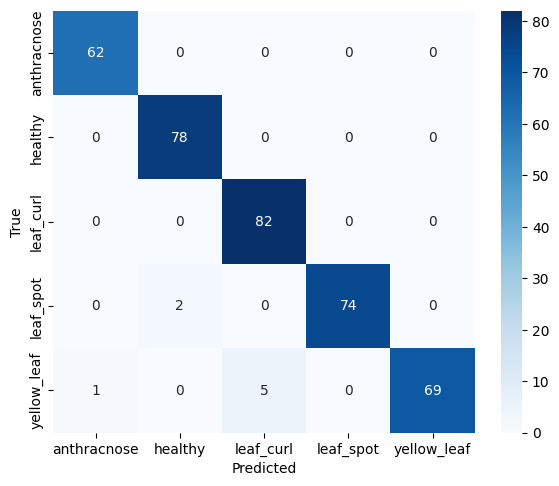

In [9]:
plot_cm(s1_labs, s1_preds, 'Confusion Matrix - C14 S1', 'c14_cm_s1.png', 'Blues')

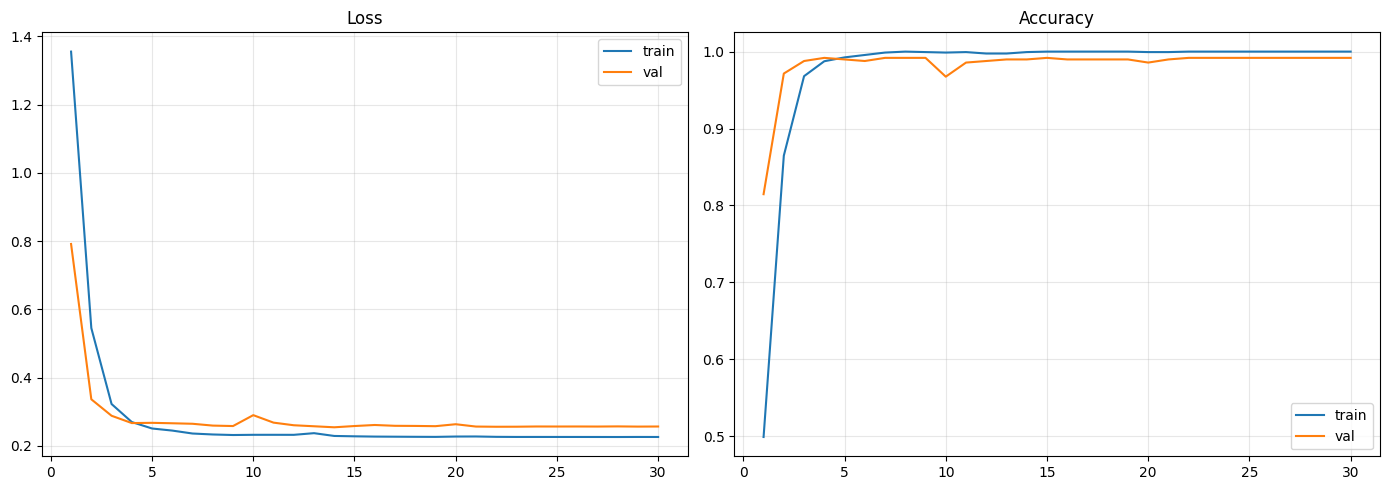

In [10]:
plot_curve(hist_s1, 'C14 - Scenario 1', 'c14_curve_s1.png')

In [11]:
torch.cuda.empty_cache(); gc.collect()

13514

## Scenario 2 — Augmented

In [ ]:
tf_aug = T.Compose([T.Resize((IMG_SIZE, IMG_SIZE)), T.RandomRotation(30),
                    T.ColorJitter(0.3, 0.3, 0.2, 0.1), T.RandomHorizontalFlip(),
                    T.RandomAffine(degrees=0, translate=(0.1, 0.1), scale=(0.85, 1.15), shear=10),
                    T.ToTensor(), T.Normalize(MEAN, STD)])
train_ds2, _ = make_train_dataset(tf_aug)   # bo A + few-shot CHI leaf_curl (neu bat)
train_loader2 = DataLoader(train_ds2, BATCH_SIZE, shuffle=True, num_workers=4, pin_memory=True)
val_loader2, test_loader2 = val_loader1, test_loader1

set_seed(SEED)
model_s2 = build_main()
set_seed(SEED)   # seed lai truoc khi train: khop dung quy trinh cua cac bien the ablation
ckpt_s2 = f'c14_s2_seed{SEED}.pth'
hist_s2 = train_model(model_s2, train_loader2, val_loader2, make_criterion(), ckpt_s2)
s2_acc, s2_f1, s2_preds, s2_labs = report(f'C14-S2 seed={SEED}', model_s2, test_loader2)

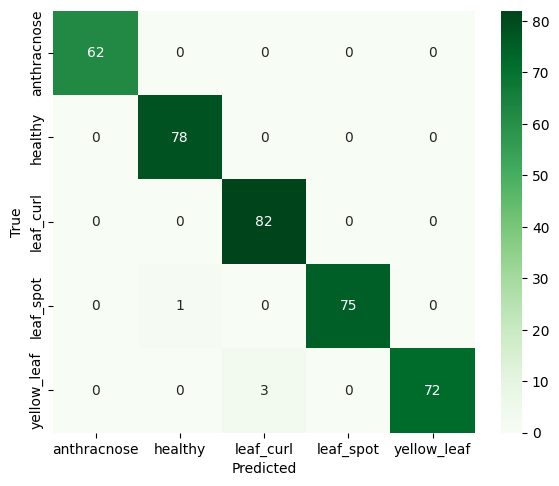

In [13]:
plot_cm(s2_labs, s2_preds, 'Confusion Matrix - C14 S2', 'c14_cm_s2.png', 'Greens')

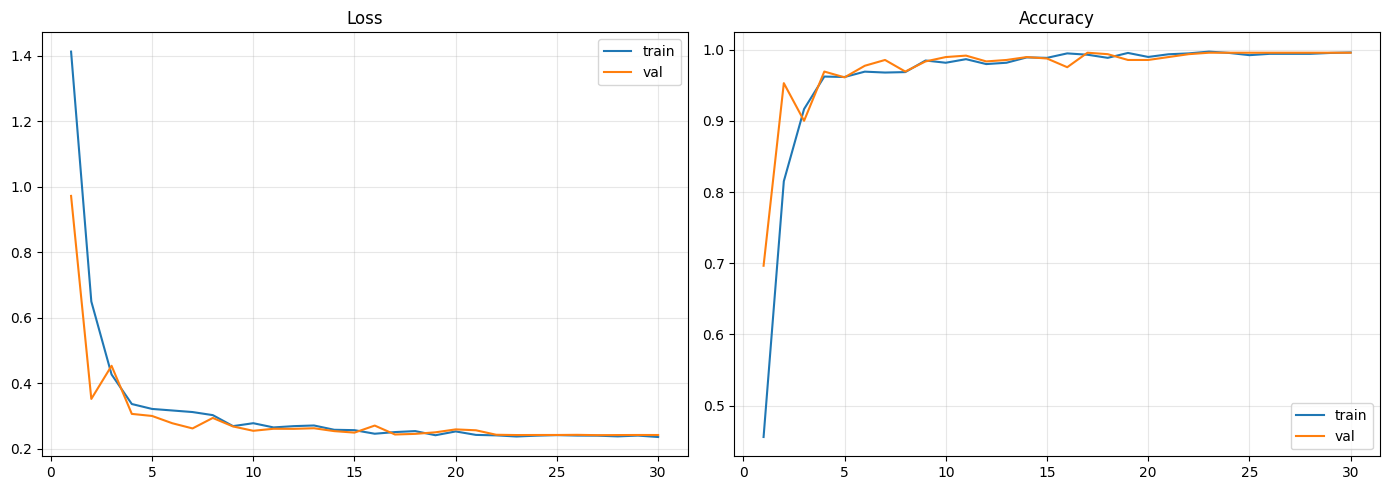

In [14]:
plot_curve(hist_s2, 'C14 - Scenario 2', 'c14_curve_s2.png')

In [15]:
import pandas as pd
df = pd.DataFrame([
    {'scenario': 'S1 baseline',  'params': count_params(model_s1), 'acc': s1_acc, 'f1': s1_f1},
    {'scenario': 'S2 augmented', 'params': count_params(model_s2), 'acc': s2_acc, 'f1': s2_f1},
])
print(df.to_string(index=False)); df.to_csv('c14_results.csv', index=False)
torch.cuda.empty_cache(); gc.collect()

    scenario  params      acc       f1
 S1 baseline  671173 0.978552 0.978951
S2 augmented  671173 0.989276 0.989727


13532